# Assignment 1: Data Preprocessing, Exploratory Data Analysis (EDA), and Regression Modeling

Due Date: [Insert Due Date]

Total Marks: 120 (including bonus)

Submission: Submit your Jupyter Notebook and the processed dataset as a CSV file through [Gradescope].



**Objective**

This assignment will help you develop essential skills in data preprocessing, exploratory data analysis (EDA), and classification. You will work with the California Housing Dataset and perform key steps to prepare the data for machine learning, including handling missing data, encoding categorical features, scaling numerical features, and generating exploratory data visualizations. In addition, you will perform feature selection based on correlation analysis and train and evaluate regression models to predict the target variable (HouseValue) based on the preprocessed features.

**Instructions**

You are provided with the California Housing Dataset, which contains information about various housing-related features in California. Your tasks are as follows:

# Part 1: Data Preprocessing

**Step 1: Load and Inspect the Data (10 Marks)**

**Tasks:**
1. Load the California Housing Dataset using scikit-learn and display the first 5 rows.
2. Check the dataset for missing values and data types.
3. Print a summary of the dataset using .info().

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt
import seaborn as sns

# Load the California Housing dataset
housing_data = fetch_california_housing(as_frame=True)
df = housing_data.frame

# Display the first few rows of the dataset
print('\n\nFirst 5 data rows :\n')  # Students fill in with the correct method to display the first 5 rows of the DataFrame
print(df[:5])
print('\n\nFirst 5 data rows :\n')
print(df.head())

# Check for missing values and data types
print('\n\nMissing values count :\n')  # Students use the correct method to print the data type info and check for missing values
print(df.isnull().sum())

print('\n\nDataset info :\n')
print(df.info())

# The following code is used by the autograder
# Ensure your final dataframe is stored in the variable step1_data for this step
step1_data = df




First 5 data rows :

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


First 5 data rows :

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.81

**Step 2: Handling Missing Data (15 Marks)**

**Tasks:**
1. Introduce missing values in the 'MedInc' (Median Income) column for rows 0 to 20.
2. Handle the missing values by imputing them with the median of the column.
3. Verify that the missing values have been correctly handled by printing the number of missing values for each column.

In [2]:
# Introduce missing values in 'MedInc' column for rows 0 to 20
df.loc[0:20, 'MedInc'] = np.nan # introduce missing values to 0-20
print('\n\nChecking first 22 rows:\n')
print(df[0:22])
print('\n\nCheck missing values count in columns:\n')
print(df.isnull().sum())

# Impute missing values in 'MedInc' using the median of the column
## fill missing values with median, median used to reduce outlier impact
df['MedInc'].fillna(df['MedInc'].median(), inplace=True)  # Students fill in the appropriate function to impute the missing values


# Verify that missing values have been handled
print('\n\nChecking first 22 rows after impute missing values:\n')
print(df[0:22])  # Students fill in with the correct method to check if any missing values remain in the DataFrame
print('\n\nCheck missing values count in columns after impute missing values:\n')
print(df.isnull().sum())

# The following code is used by the autograder
# Ensure your final dataframe is stored in the variable step2_data for this step
step2_data = df




Checking first 22 rows:

    MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0      NaN      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1      NaN      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2      NaN      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3      NaN      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4      NaN      52.0  6.281853   1.081081       565.0  2.181467     37.85   
5      NaN      52.0  4.761658   1.103627       413.0  2.139896     37.85   
6      NaN      52.0  4.931907   0.951362      1094.0  2.128405     37.84   
7      NaN      52.0  4.797527   1.061824      1157.0  1.788253     37.84   
8      NaN      42.0  4.294118   1.117647      1206.0  2.026891     37.84   
9      NaN      52.0  4.970588   0.990196      1551.0  2.172269     37.84   
10     NaN      52.0  5.477612   1.079602       910.0  2.263682     37.85   
11     NaN      52.0  4.772480   1.024523      15

/var/folders/l4/5pw1zvn16fv694mg4r8n5v8c0000gn/T/ipykernel_79427/3109623557.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['MedInc'].fillna(df['MedInc'].median(), inplace=True)  # Students fill in the appropriate function to impute the missing values


Step 3: Encoding Categorical Features (20 Marks)

Tasks:

1. Create a new categorical feature called HouseAgeCat by binning the HouseAge column into three categories:

* Young: 0–20 years

* Middle-Aged: 21–40 years

* Old: 41–60 years

2. Perform one-hot encoding on the HouseAgeCat feature, ensuring that one category is dropped (drop_first=True).

3. Print the first 5 rows of the dataset to verify that the encoding was done correctly.

In [3]:
# Create a categorical feature 'HouseAgeCat' by binning the 'HouseAge' column
# (0-20] - young
# (20, 40] - middle-aged
# (40, 60] - old
df['HouseAgeCat'] = pd.cut(df['HouseAge'], bins=[0, 20, 40, 60], labels=['Young', 'Middle-Aged', 'Old'])  # Students complete labels for the 'Middle-Aged' and 'Old' categories

# Perform one-hot encoding on 'HouseAgeCat'
# used drop_first to avoid multicollinearity
df_encoded = pd.get_dummies(df, columns=['HouseAgeCat'], drop_first=True)  # Students complete with the correct column name and drop_first argument

# Verify the encoding by printing the first 5 rows of the dataset
print('\n\nPrint first 5 rows with new categorical feature:\n')
print(df_encoded.head())  # Students print the first 5 rows of the encoded DataFrame

# The following code is used by the autograder
# Ensure your final encoded dataframe is stored in the variable step3_data for this step
step3_data = df_encoded




Print first 5 rows with new categorical feature:

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  3.5352      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  3.5352      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  3.5352      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  3.5352      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.5352      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  HouseAgeCat_Middle-Aged  HouseAgeCat_Old  
0    -122.23        4.526                    False             True  
1    -122.22        3.585                     True            False  
2    -122.24        3.521                    False             True  
3    -122.25        3.413                    False             True  
4    -122.25        3.422                    False             True  


Step 4: Feature Scaling (20 Marks)

Tasks:

1. Select all the numerical features from the dataset (excluding the target variable and any categorical columns).
2. Standardize the numerical features using StandardScaler to have a mean of 0 and a standard deviation of 1.
3. Verify that the features have been correctly scaled by printing the mean and standard deviation for each feature.

In [4]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns (excluding target variable and categorical columns)
numerical_columns = ['MedInc', 'HouseAge', 'AveRooms', 
                     'AveBedrms', 'Population', 'AveOccup', 
                     'Latitude', 'Longitude']  # Students complete the list of numerical features (e.g., 'MedInc', 'HouseAge', etc.)

# Initialize the scaler
scaler = StandardScaler()

# Scale the numerical features
df_encoded[numerical_columns] = scaler.fit_transform(df_encoded[numerical_columns])  # Students fill in the correct DataFrame and columns to be scaled

# Check the mean and standard deviation
print('\n\nPrinting the mean of numerical columns:\n ')
print(df_encoded[numerical_columns].mean())  # Students print the mean of the scaled features
print('\n\nPrinting the standard deviation of numerical columns:\n ')
print(df_encoded[numerical_columns].std())  # Students print the standard deviation of the scaled features

# The following code is used by the autograder
# Ensure your scaled dataframe is stored in the variable step4_data for this step
step4_data = df_encoded




Printing the mean of numerical columns:
 
MedInc        2.919284e-16
HouseAge      5.508083e-18
AveRooms      6.609700e-17
AveBedrms    -1.060306e-16
Population   -1.101617e-17
AveOccup      3.442552e-18
Latitude     -1.079584e-15
Longitude    -8.526513e-15
dtype: float64


Printing the standard deviation of numerical columns:
 
MedInc        1.000024
HouseAge      1.000024
AveRooms      1.000024
AveBedrms     1.000024
Population    1.000024
AveOccup      1.000024
Latitude      1.000024
Longitude     1.000024
dtype: float64


# Part2: Exploratory Data Analysis (EDA)

Step 5: Exploratory Data Analysis (EDA) (20 Marks)

Tasks:

1. Summary Statistics: Compute and print the summary statistics (mean, median, standard deviation, etc.) for the numerical features using .describe().

2. Histograms: Plot histograms for the numerical features to visualize their distributions.
3. Scatter Plot: Create a scatter plot to visualize the relationship between MedInc (median income) and the target variable HouseValue.



Printing the stats about each column:

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  2.064000e+04  2.064000e+04  2.064000e+04  2.064000e+04  2.064000e+04   
mean   2.919284e-16  5.508083e-18  6.609700e-17 -1.060306e-16 -1.101617e-17   
std    1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00   
min   -1.775193e+00 -2.196180e+00 -1.852319e+00 -1.610768e+00 -1.256123e+00   
25%   -6.879075e-01 -8.453931e-01 -3.994496e-01 -1.911716e-01 -5.638089e-01   
50%   -1.766084e-01  2.864572e-02 -8.078489e-02 -1.010650e-01 -2.291318e-01   
75%    4.591284e-01  6.643103e-01  2.519615e-01  6.015869e-03  2.644949e-01   
max    5.861548e+00  1.856182e+00  5.516324e+01  6.957171e+01  3.025033e+01   

           AveOccup      Latitude     Longitude  
count  2.064000e+04  2.064000e+04  2.064000e+04  
mean   3.442552e-18 -1.079584e-15 -8.526513e-15  
std    1.000024e+00  1.000024e+00  1.000024e+00  
min   -2.290000e-01 -1.447568e+00 -2.385992e+00

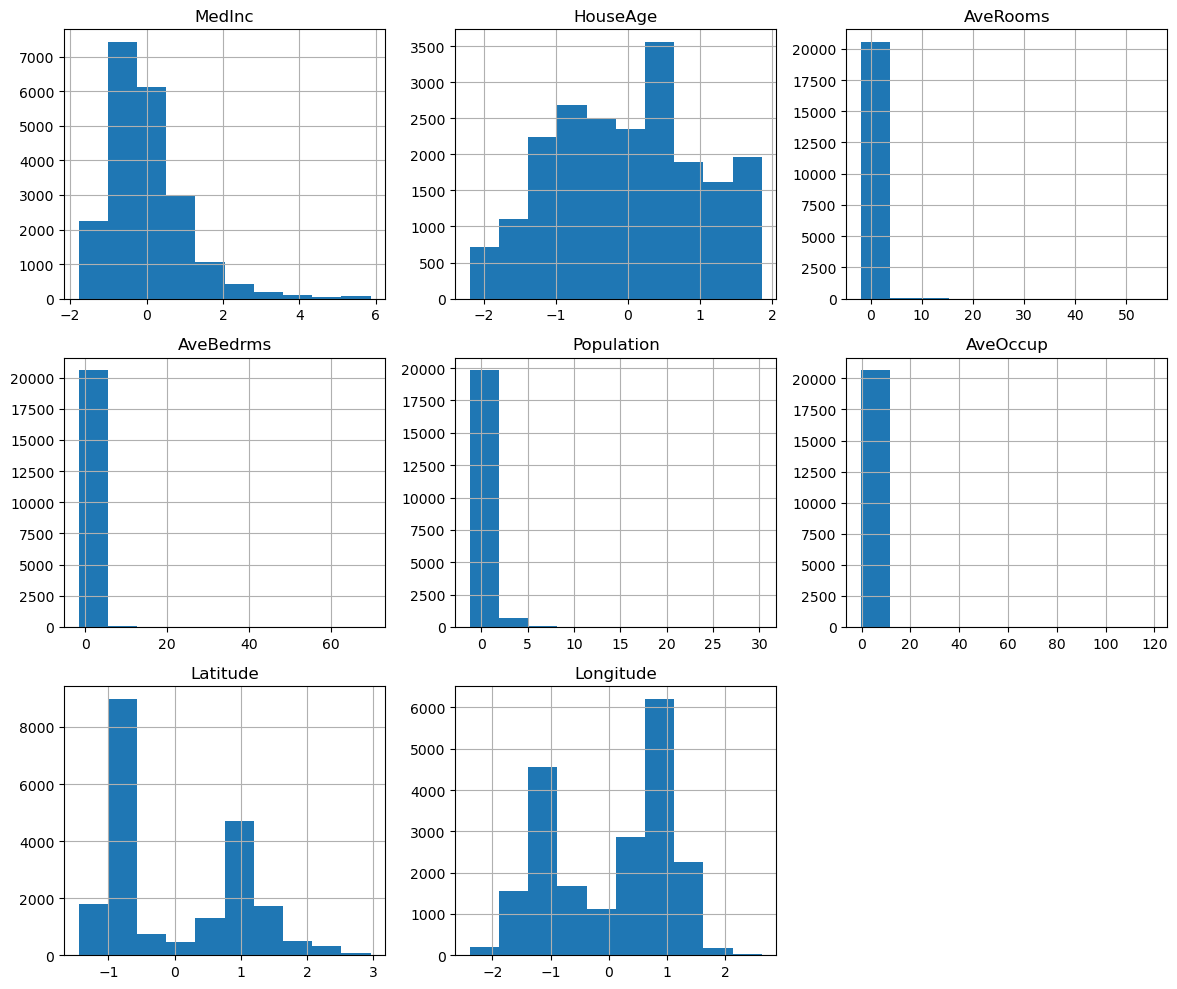

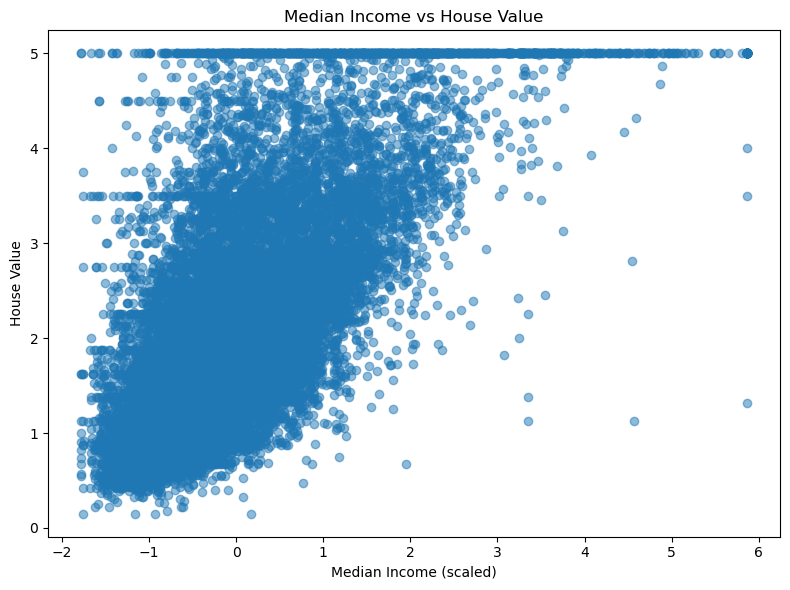

In [5]:
# Compute summary statistics for the numerical features
# Students will complete the code below
summary_statistics = df_encoded[numerical_columns].describe()
print('\n\nPrinting the stats about each column:\n')
print(summary_statistics)
print()

# Plot histograms for numerical features
# Students will complete this part
# ...
# setting up histogram
df_encoded[numerical_columns].hist(figsize=(12,10))
plt.tight_layout()
plt.show()

# Scatter plot of 'MedInc' vs 'HouseValue'
# Students need to complete the code to generate the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df_encoded['MedInc'], df_encoded['MedHouseVal'], alpha=0.5)  # Students will fill in the required columns
plt.xlabel('Median Income (scaled)')
plt.ylabel('House Value')
plt.title('Median Income vs House Value')
plt.tight_layout()
plt.show()

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step5_data
step5_data = summary_statistics


Step 6: Feature Selection (15 Marks)

Tasks:

1. Correlation Matrix: Computes the correlation matrix of the dataset and convert all the correlation values to their absolute values.
2. Feature Selection: Based on the correlation matrix, identify and print if there are any pairs of features with high correlation (above 0.8).
3. Drop the highly correlated features obtained in Task 2.



Correlation values for each column:

                           MedInc  HouseAge  AveRooms  AveBedrms  Population  \
MedInc                   1.000000  0.118921  0.326732   0.062038    0.004804   
HouseAge                 0.118921  1.000000  0.153277   0.077747    0.296244   
AveRooms                 0.326732  0.153277  1.000000   0.847621    0.072213   
AveBedrms                0.062038  0.077747  0.847621   1.000000    0.066197   
Population               0.004804  0.296244  0.072213   0.066197    1.000000   
AveOccup                 0.018774  0.013191  0.004852   0.006181    0.069863   
Latitude                 0.079931  0.011173  0.106389   0.069721    0.108785   
Longitude                0.015093  0.108197  0.027540   0.013344    0.099773   
MedHouseVal              0.687724  0.105623  0.151948   0.046701    0.024650   
HouseAgeCat_Middle-Aged  0.027686  0.166427  0.056846   0.039107    0.066889   
HouseAgeCat_Old          0.077908  0.706460  0.091334   0.039758    0.176639   



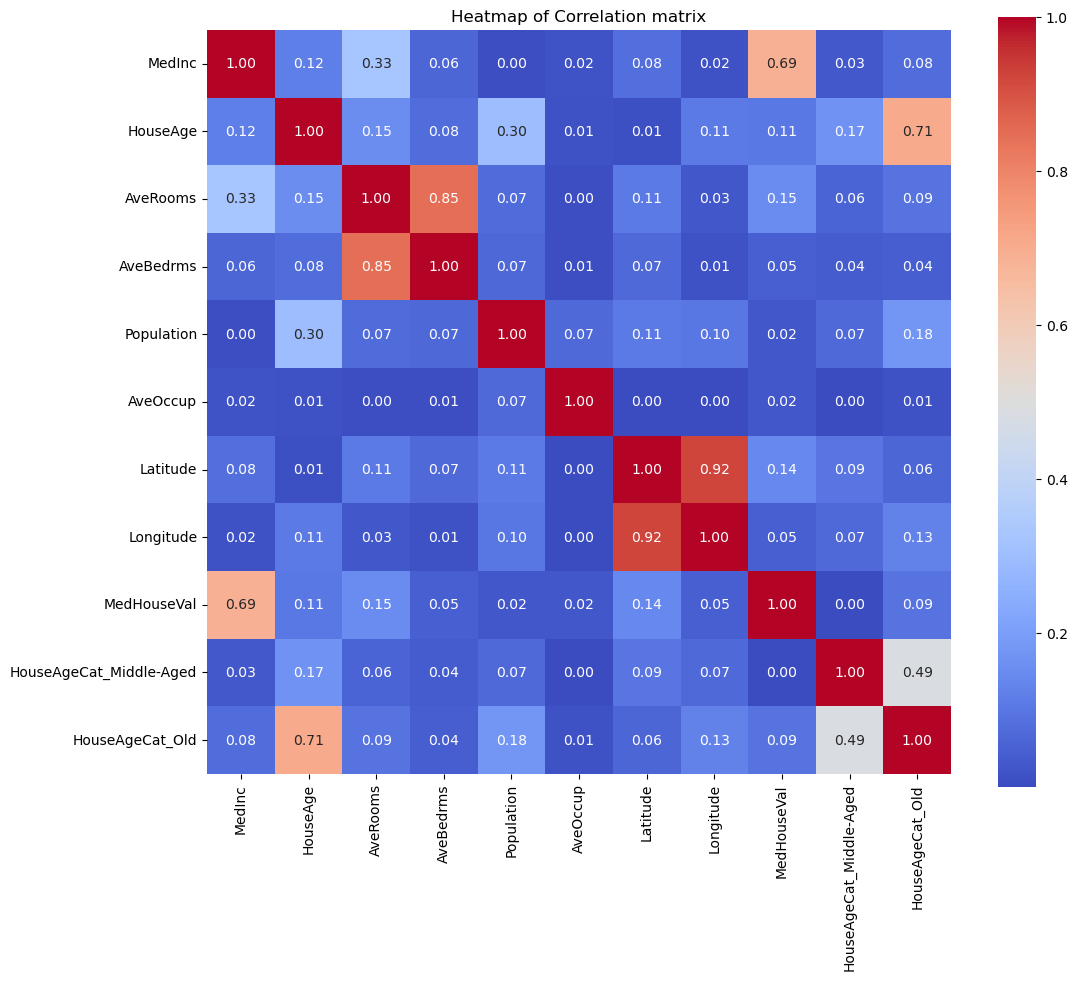



Highly correlated features in dataset:

                         MedInc  HouseAge  AveRooms  AveBedrms  Population  \
MedInc                      NaN  0.118921  0.326732   0.062038    0.004804   
HouseAge                    NaN       NaN  0.153277   0.077747    0.296244   
AveRooms                    NaN       NaN       NaN   0.847621    0.072213   
AveBedrms                   NaN       NaN       NaN        NaN    0.066197   
Population                  NaN       NaN       NaN        NaN         NaN   
AveOccup                    NaN       NaN       NaN        NaN         NaN   
Latitude                    NaN       NaN       NaN        NaN         NaN   
Longitude                   NaN       NaN       NaN        NaN         NaN   
MedHouseVal                 NaN       NaN       NaN        NaN         NaN   
HouseAgeCat_Middle-Aged     NaN       NaN       NaN        NaN         NaN   
HouseAgeCat_Old             NaN       NaN       NaN        NaN         NaN   

                     

In [6]:
# Compute correlation matrix and convert to absolute values
# Students will complete the code
corr_matrix = df_encoded.corr().abs() # correlation matrix

# Display correlation matrix
# Students complete this part to visualize the correlation matrix
# ...
print('\n\nCorrelation values for each column:\n')
print(corr_matrix)

# heatmap visualization
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Heatmap of Correlation matrix')
plt.show()


# Identify highly correlated features (above 0.8)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
print('\n\nHighly correlated features in dataset:\n')
print(upper)
print('\n')

# Students complete the following code to find features to drop
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]

# Print the features that will be dropped
print(f"Highly correlated features to drop: {to_drop}")

# Drop the highly correlated features
# Students complete the code to drop the selected features
df_encoded.drop(to_drop, axis=1, inplace=True)
print('dataset after dropping highly correlated features')
print(df_encoded)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step6_data
step6_data = to_drop


**Step 7: Saving ans splitting the Processed Dataset (5 Marks)**

**Tasks:**

1. Save the processed dataset (with imputed missing values, encoded categorical features, and scaled numerical features) as a CSV file named preprocessed_housing_data.csv.
2.  Split the dataset into training and testing sets: Use train_test_split from sklearn.model_selection to split the preprocessed dataset into training and testing sets. Use 80% of the data for training and 20% for testing and random_state=42.

In [7]:
# Save the processed dataset to a CSV file
# Students complete this line to save the preprocessed dataset
df_encoded.to_csv('preprocessed_housing_data.csv', index=False)

# Import train_test_split for splitting the dataset
from sklearn.model_selection import train_test_split

# Define features and target variable
X = df_encoded.drop('MedHouseVal', axis=1)  # Students complete the feature selection
y = df_encoded['MedHouseVal']  # Students complete the target variable selection

# Split the dataset into training and testing sets
# Students complete the train_test_split function
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # train test split of 80/20

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step7_data
step7_data = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}
print('\n\nFeature sizes:')
print(X_train.shape, X_test.shape)
print('\n\nLabel sizes:')
print(y_train.shape, y_test.shape)


assert X_train.shape[1] == X_test.shape[1]



Feature sizes:
(16512, 8) (4128, 8)


Label sizes:
(16512,) (4128,)


# Part 3: Regression Modeling

**Objective:** In this section, you will train and evaluate regression models to predict the target variable (HouseValue) based on the preprocessed features.

Step 8: Linear Regression model (5 marks)

Tasks:
 1. Train a **Linear Regression model** using the training data
 2. Make predictions on the test data
 3. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R-squared (R²) score.

In [8]:
# Import necessary libraries for Linear Regression and evaluation metrics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Train a Linear Regression model on the training data
# Students complete this by initializing and fitting the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions on the test data
# Students complete the prediction step
y_pred = lr_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R-squared (R²) score
mse = mean_squared_error(y_test, y_pred)  # Students complete MSE calculation
r2 = r2_score(y_test, y_pred)  # Students complete R² score calculation

# Output the results
print(f"Linear Regression - MSE: {mse:.2f}, R²: {r2:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step8_data
step8_data = {'mse': mse, 'r2': r2}


Linear Regression - MSE: 0.65, R²: 0.50


**Step 9: Polynomial Regression model** (5 marks)

Tasks:

1. Transform the features using polynomial terms of degree 2
2. Train a **Polynomial Regression model** on the transformed training data and make predictions on the transformed test data.
3. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R-squared (R²) score.

In [9]:
# Import necessary libraries for Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Transform the features using polynomial terms of degree 2
# Students complete this by fitting and transforming the training data
poly_features = PolynomialFeatures(degree=2)
X_train_poly = poly_features.fit_transform(X_train)  # Students complete the transformation for training data
X_test_poly = poly_features.transform(X_test)  # Students complete the transformation for test data

# Train a Polynomial Regression model on the transformed training data
# Students complete this by initializing and fitting the model
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Make predictions on the transformed test data
# Students complete the prediction step
y_pred_poly = poly_model.predict(X_test_poly)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R-squared (R²) score
mse_poly = mean_squared_error(y_test, y_pred_poly)  # Students complete MSE calculation
r2_poly = r2_score(y_test, y_pred_poly)  # Students complete R² score calculation

# Output the results
print(f"Polynomial Regression - MSE: {mse_poly:.2f}, R²: {r2_poly:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step9_data
step9_data = {'mse_poly': mse_poly, 'r2_poly': r2_poly}


Polynomial Regression - MSE: 0.55, R²: 0.58


**Step 10: Decision Tree Regressor** (5 marks)

Tasks:
1. Train a Decision Tree Regressor with a maximum depth of 10.
2. Use the training data to fit the model.
3. Make predictions using the test data.
4. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R² score.

In [10]:
# Import necessary libraries for Decision Tree Regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Train a Decision Tree Regressor with a maximum depth of 10
# Students complete this by initializing the Decision Tree model
tree_model = DecisionTreeRegressor(max_depth=10, random_state=42)

# Fit the model using the training data
# Students complete the model fitting step
tree_model.fit(X_train, y_train)

# Make predictions using the test data
# Students complete the prediction step
y_pred_tree = tree_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_tree = mean_squared_error(y_test, y_pred_tree)  # Students complete MSE calculation
r2_tree = r2_score(y_test, y_pred_tree)   # Students complete R² score calculation

# Output the results
print(f"Decision Tree Regression - MSE: {mse_tree:.2f}, R²: {r2_tree:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step10_data
step10_data = {'mse_tree': mse_tree, 'r2_tree': r2_tree}


Decision Tree Regression - MSE: 0.50, R²: 0.62


**Step 11:Random Forest Regressor** (5 marks)

Tasks:
1. Train a Random Forest Regressor with 100 estimators (trees).
2. Fit the model using the training data.
3. Make predictions using the test data.
4. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R² score.

In [15]:
# Import necessary libraries for Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Step 11: Train a Random Forest Regressor with 100 estimators
# Students need to complete the model initialization
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Fit the model using the training data
# Students complete the model fitting step
rf_model.fit(X_train, y_train)

# Make predictions using the test data
# Students complete the prediction step
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_rf = mean_squared_error(y_test, y_pred_rf)  # Students complete MSE calculation
r2_rf = r2_score(y_test, y_pred_rf)   # Students complete R² score calculation

# Output the results
print(f"Random Forest Regression - MSE: {mse_rf:.2f}, R²: {r2_rf:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step11_data
step11_data = {'mse_rf': mse_rf, 'r2_rf': r2_rf}


Random Forest Regression - MSE: 0.36, R²: 0.72


**Step 12:Support Vector Regression (SVR) model** (5 marks)

Tasks:

1. Train a Support Vector Regression (SVR) model using the Radial Basis Function (RBF) kernel (Set regularization parameter C=100, kernel coefficient γ=0.1, and ϵ=0.1).
2. Fit the model on the training data.
3. Make predictions on the test data.
4. Evaluate the model using Mean Squared Error (MSE) and R² score to assess its performance.

In [12]:
# Import necessary libraries for Support Vector Regression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Step 12: Train a Support Vector Regression (SVR) model using the RBF kernel
# Students need to complete the model initialization with the given parameters
svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)  # Students fill in the parameters: kernel='rbf', C=100, gamma=0.1, epsilon=0.1

# Fit the model on the training data
# Students complete the model fitting step
svr_model.fit(X_train, y_train)

# Make predictions on the test data
# Students complete the prediction step
y_pred_svr = svr_model.predict(X_test)

# Evaluate the SVR model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_svr = mean_squared_error(y_test, y_pred_svr)  # Students complete MSE calculation
r2_svr = r2_score(y_test, y_pred_svr)   # Students complete R² score calculation

# Output the results
print(f"Support Vector Regression - MSE: {mse_svr:.2f}, R²: {r2_svr:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step12_data
step12_data = {'mse_svr': mse_svr, 'r2_svr': r2_svr}


Support Vector Regression - MSE: 0.44, R²: 0.66


Step 13:

Tasks: Write answers for following:

* **Analyse Performance of Regression Models?**
* **Which one performed best and why?**

|model|Mean Square Error|R²|
|-|-|-|
|Linear Regression|0.65|0.50|
|Polynomial Regression|0.55|0.58|
|Decision Tree Regression|0.50|0.62|
|Random Forest Regression|0.36|0.72|
|Support Vector Regression|0.44|0.66|


### Linear Regression
It's the simplest model we have used, uses linear relationships between features and target. high MSE and low R² indicates that it can't perform well for non linear relationships


### Polynomial Regression
It adds non linear terms to handle non linear relationships, here we have used degree 2. Improvement of MSE and R² show that it performs better than Linear Regression for the dataset

### Decision Tree Regression
Decision tree can model non linear relationships. Both MSE and R² have been improved, indicating it fits data better than Linear Regression and Polynomial Regression. Controlling the max depth can be tricky, here we used 10.

### Random Forest Regression
Ensemble learning with combination of multiple Decision Trees to perform better. Gives Best performance of all models with MSE=0.36 and R²=0.72. We can conclude as it captures complex nonlinear patterns.

### Support Vector Regression
RBF kernel is used to handle nonlinearity. Performs better than Linear Regression, Polynomial Regression, Decision Tree Regression, but slightly underperforms than Random Forest Regression. Parameter tunining is the trick for better performance.


### Best Performce by Random Forest Regression
It ensembles learning with combination of multiple Decision Trees to perform better, causing to reduce variance and overfitting. It helps to capture complex patterns. we can change n_estimator value and evaluate the performance of the model.